# EDA - BatteryAgent Control Strategy & Forecasting Pipeline
## UPC Sostenible Datathon 2026 - Exploratory Data Analysis

This EDA bridges **data engineering** (cleaning 5-minute sensor telemetry into reliable hourly series),
**physical domain understanding** (how the campus consumes and generates energy), and
**control optimization** (how price, CO², and net load interact under battery physics).

---

### Structure
1. **Data Integrity, Alignment & Preprocessing** - Temporal coverage, missing values, physical sanity checks
2. **Campus Demand & Solar Generation Dynamics** - Load profiles, solar patterns, net load, autocorrelation
3. **Market Price & Grid Carbon Dynamics** - PVPC/CO² correlation, composite marginal value, arbitrage potential
4. **Baseline Simulation & Oracle Upper Bound** - Benchmark totals, LP-based optimal control analysis

---
## 0. Setup & Configuration

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from pathlib import Path
from datetime import datetime, timedelta
from scipy import stats as scipy_stats
import warnings

warnings.filterwarnings('ignore')

plt.rcParams.update({
    'figure.figsize': (14, 6),
    'figure.dpi': 100,
    'font.size': 11,
    'axes.titlesize': 13,
    'axes.labelsize': 11,
})

# Battery specs
BATTERY_CAPACITY_KWH = 2000
BATTERY_POWER_KW = 500
BATTERY_EFFICIENCY = 0.90
ETA_CHARGE = np.sqrt(BATTERY_EFFICIENCY)
ETA_DISCHARGE = np.sqrt(BATTERY_EFFICIENCY)
SOC_INIT_KWH = BATTERY_CAPACITY_KWH * 0.5  # 1000 kWh
ARBITRAGE_SPREAD_THRESHOLD = 1.0 / BATTERY_EFFICIENCY  # ~1.111

DATA_DIR = Path("../data/train") if Path("../data/train").exists() else Path("data/train")

print(f"Data directory: {DATA_DIR.absolute()}")
print(f"Battery: {BATTERY_CAPACITY_KWH} kWh / {BATTERY_POWER_KW} kW, eta={BATTERY_EFFICIENCY}")
print(f"Arbitrage spread hurdle: {ARBITRAGE_SPREAD_THRESHOLD:.3f}x (11.1%)")


Data directory: d:\Git\DatathonFME_UPCSostenibleChallenge\notebooks\..\data\train
Battery: 2000 kWh / 500 kW, eta=0.9
Arbitrage spread hurdle: 1.111x (11.1%)


---
## 1. Data Integrity, Alignment & Preprocessing Checks

Before analyzing physical patterns, verify how the 6 CSV files align and where sensor artifacts occur.

### 1.1 Temporal Coverage & Test Split Verification
- Confirm the exact date range (Sept 2025 - Sept 2026)
- Verify that the last 7 days of every calendar month are missing in data/train/ (hidden test set)
- Check timezone consistency and DST transitions across all 6 files
- Look for duplicate timestamps or missing hours

In [2]:
files_map = {
    'contador': DATA_DIR / 'contador.csv',
    'inversor': DATA_DIR / 'inversor.csv',
    'meteo': DATA_DIR / 'meteo.csv',
    'entrades': DATA_DIR / 'entradas_salidas.csv',
    'precio': DATA_DIR / 'precio_pvpc.csv',
    'co2': DATA_DIR / 'co2_red.csv',
}

dfs_raw = {}
for name, path in files_map.items():
    dfs_raw[name] = pd.read_csv(path, parse_dates=['Fecha'])
    print(f"{name:12s}: {dfs_raw[name].shape[0]:7d} rows,  {dfs_raw[name]['Fecha'].min()}  to  {dfs_raw[name]['Fecha'].max()}")

print('\n--- Temporal coverage summary ---')
coverage = pd.DataFrame({
    'file': list(files_map.keys()),
    'first_ts': [dfs_raw[n]['Fecha'].min() for n in files_map],
    'last_ts': [dfs_raw[n]['Fecha'].max() for n in files_map],
    'n_rows': [dfs_raw[n].shape[0] for n in files_map],
})
coverage['date_range'] = [(pd.to_datetime(coverage.loc[i,'last_ts']) -
                          pd.to_datetime(coverage.loc[i,'first_ts'])).days
                         for i in coverage.index]
print(coverage.to_string(index=False))

print('\n--- Expected full range (1 year) ---')
print('  Should span: 2025-09-01 00:00 to 2026-08-31 23:00')
print('  Last 7 days of each month excluded (hidden test)')


contador    :   74210 rows,  2025-09-01 00:05:00  to  2026-09-01 00:00:00
inversor    :   71882 rows,  2025-09-01 00:05:00  to  2026-08-16 22:00:00
meteo       :   74210 rows,  2025-09-01 00:05:00  to  2026-09-01 00:00:00
entrades    :   74210 rows,  2025-09-01 00:05:00  to  2026-09-01 00:00:00
precio      :    6768 rows,  2025-09-01 00:00:00  to  2026-09-01 23:00:00
co2         :    6768 rows,  2025-09-01 00:00:00  to  2026-09-01 23:00:00

--- Temporal coverage summary ---
    file            first_ts             last_ts  n_rows  date_range
contador 2025-09-01 00:05:00 2026-09-01 00:00:00   74210         364
inversor 2025-09-01 00:05:00 2026-08-16 22:00:00   71882         349
   meteo 2025-09-01 00:05:00 2026-09-01 00:00:00   74210         364
entrades 2025-09-01 00:05:00 2026-09-01 00:00:00   74210         364
  precio 2025-09-01 00:00:00 2026-09-01 23:00:00    6768         365
     co2 2025-09-01 00:00:00 2026-09-01 23:00:00    6768         365

--- Expected full range (1 year) ---


#### 1.1.1 Hidden test set verification
The last 7 days of every month form the hidden test set. Let's verify the gaps.

In [3]:
print('=== Gap analysis (potential test split boundaries) ===')
for name, df in dfs_raw.items():
    if len(df) < 2:
        continue
    df_sorted = df.sort_values('Fecha')
    diffs = df_sorted['Fecha'].diff().dt.total_seconds() / 3600.0
    big_gaps = diffs[diffs > 24].dropna()
    if len(big_gaps) > 0:
        print(f'\n{name}: {len(big_gaps)} gaps > 24h:')
        for i, idx in enumerate(big_gaps.index[:20]):
            prev_ts = df_sorted.loc[idx - 1, 'Fecha'] if idx > 0 else None
            gap_hours = big_gaps.loc[idx]
            if prev_ts:
                print(f"  {i+1}. {prev_ts} -> gap {gap_hours:.1f}h -> {df_sorted.loc[idx, 'Fecha']}")


=== Gap analysis (potential test split boundaries) ===

contador: 12 gaps > 24h:
  1. 2025-09-23 23:55:00 -> gap 168.1h -> 2025-10-01 00:00:00
  2. 2025-10-24 23:55:00 -> gap 168.1h -> 2025-11-01 00:00:00
  3. 2025-11-01 00:00:00 -> gap 720.0h -> 2025-12-01 00:00:00
  4. 2025-12-24 23:55:00 -> gap 168.1h -> 2026-01-01 00:00:00
  5. 2026-01-24 23:55:00 -> gap 168.1h -> 2026-02-01 00:00:00
  6. 2026-02-21 23:55:00 -> gap 168.1h -> 2026-03-01 00:00:00
  7. 2026-03-24 23:55:00 -> gap 168.1h -> 2026-04-01 00:00:00
  8. 2026-04-23 23:55:00 -> gap 168.1h -> 2026-05-01 00:00:00
  9. 2026-05-24 23:55:00 -> gap 168.1h -> 2026-06-01 00:00:00
  10. 2026-06-23 23:55:00 -> gap 168.1h -> 2026-07-01 00:00:00
  11. 2026-07-24 23:55:00 -> gap 168.1h -> 2026-08-01 00:00:00
  12. 2026-08-24 23:55:00 -> gap 168.1h -> 2026-09-01 00:00:00

inversor: 11 gaps > 24h:
  1. 2025-09-23 23:55:00 -> gap 168.1h -> 2025-10-01 00:00:00
  2. 2025-10-24 23:55:00 -> gap 168.1h -> 2025-11-01 00:00:00
  3. 2025-11-01 00:00:

### 1.2 Missing Values & Communication Diagnostics
- Audit ESTADO COM and CALIDAD COM in contador.csv
- Quantify frequency and duration of drops (CALIDAD COM < 100)
- Check NaN rates across all 5-minute files vs 1-hour files
- Visualize missingness patterns with missingno

In [4]:
# === missingno visualizations ===
# First, install if needed: pip install missingno
try:
    import missingno as msno
    print('missingno loaded successfully')
except ImportError:
    print('missingnot installed - try: pip install missingno')
    msno = None

# Quick stats before plotting
print('\n=== NaN rates (%) by file ===')
for name, df in dfs_raw.items():
    total_cells = df.shape[0] * df.shape[1]
    nan_cells = df.isna().sum().sum()
    nan_pct = 100.0 * nan_cells / total_cells if total_cells > 0 else 0
    nans_per_col = df.isna().sum()
    cols_with_nans = nans_per_col[nans_per_col > 0]
    print(f"{name:12s}: {nan_pct:6.2f}% ({nan_cells:,} / {total_cells:,} cells)")
    if len(cols_with_nans) > 0:
        top_nan = cols_with_nans.nlargest(3)
        print(f"           Top-NaN columns: {dict(top_nan)}")
    print()


missingnot installed - try: pip install missingno

=== NaN rates (%) by file ===
contador    :   3.51% (75,438 / 2,152,090 cells)
           Top-NaN columns: {'Meter 1 - ULTIMA FECHA CURVA DE CARGA': np.int64(74210), 'Contador - ENERGIA ACTIVA EXPORTADA (kWh)': np.int64(195), 'Contador - ENERGIA ACTIVA IMPORTADA (kWh)': np.int64(195)}

inversor    :   1.71% (216,037 / 12,651,232 cells)
           Top-NaN columns: {'Inversor 2 - NUMERO DE FALLOS': np.int64(69108), 'Inversor 1 - NUMERO DE FALLOS': np.int64(67899), 'Inversor 3 - NUMERO DE FALLOS': np.int64(66963)}

meteo       :   5.00% (74,259 / 1,484,200 cells)
           Top-NaN columns: {'Atersa - NUMERO DE FALLOS': np.int64(74210), 'Atersa - MARCA': np.int64(3), 'Atersa - MODELO': np.int64(3)}

entrades    :  49.47% (734,261 / 1,484,200 cells)
           Top-NaN columns: {'IoLogik 1214 - MARCA.1': np.int64(74210), 'IoLogik 1214 - MODELO.1': np.int64(74210), 'IoLogik 1214 - ESTADO COM.1': np.int64(74210)}

precio      :   0.00% (0 / 2

AttributeError: 'NoneType' object has no attribute 'bar'

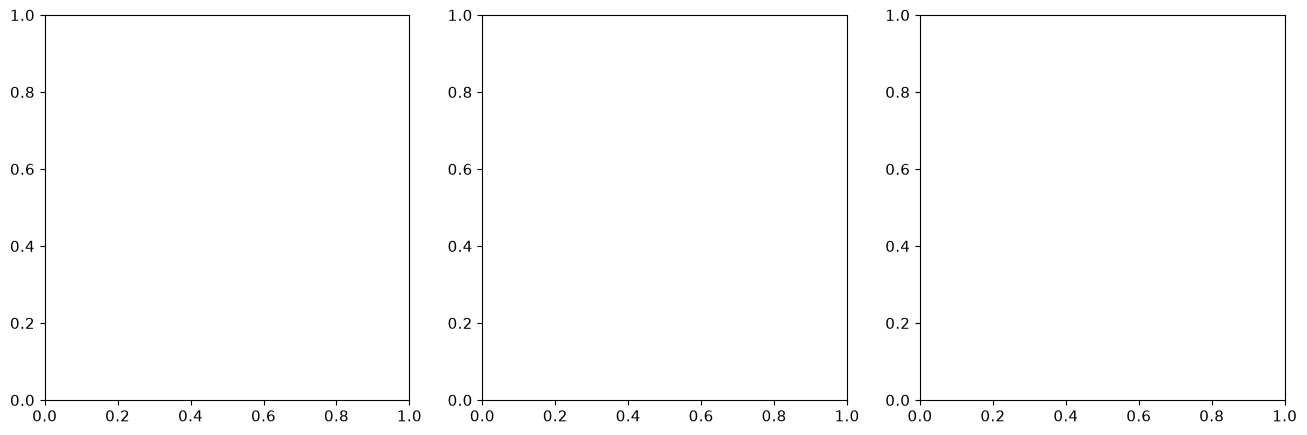

: 

In [ ]:
if msno is not None:
    # Plot 1: Missingno matrix for each 5-min file (sampled)
    fig = plt.figure(figsize=(20, 5))
    
    for i, name in enumerate(['contador', 'inversor', 'meteo']):
        if i == 0:
            ax = fig.add_subplot(1, 3, 1)
            # Sample for visualization
            df_sample = dfs_raw[name].drop(columns=['Fecha'], errors='ignore')
            msno.matrix(df_sample, ax=ax, sparkline=False)
            ax.set_title(f'{name}: Missingness Matrix (all cols)')
        elif i == 1:
            ax = fig.add_subplot(1, 3, 2)
            df_sample = dfs_raw[name].drop(columns=['Fecha'], errors='ignore')
            # For inversor, select first 20 numeric cols for readability
            cols_to_show = df_sample.select_dtypes(include=[np.number]).columns[:20]
            df_sample20 = df_sample[cols_to_show]
            msno.matrix(df_sample20, ax=ax, sparkline=False)
            ax.set_title(f'{name}: Key Columns (first 20 numeric)')
        elif i == 2:
            ax = fig.add_subplot(1, 3, 3)
            df_sample = dfs_raw[name].drop(columns=['Fecha'], errors='ignore')
            msno.matrix(df_sample, ax=ax, sparkline=False)
            ax.set_title(f'{name}: Missingness Matrix')
    
    fig.suptitle('Missingno Matrix - 5-min Files (Sampled)', fontsize=14, y=1.02)
    fig.tight_layout()
    plt.savefig('01eda_missingno_matrix.png', dpi=150, bbox_inches='tight')
    print('Saved: 01eda_missingno_matrix.png')
    plt.show()

# Plot 2: missingno bar chart for all files
fig = plt.figure(figsize=(16, 5))
axes = fig.subplots(1, 3)

for i, name in enumerate(['contador', 'inversor', 'meteo']):
    df_sample = dfs_raw[name].drop(columns=['Fecha'], errors='ignore')
    cols_to_show = df_sample.select_dtypes(include=[np.number]).columns[:15]
    df_sub = df_sample[cols_to_show]
    msno.bar(df_sub, ax=axes[i], color='coral', fontsize=8)
    axes[i].set_title(f'{name}: NaN Count (top 15 numeric cols)', fontsize=10)

fig.suptitle('Missingno Bar Chart - NaN Counts', fontsize=14, y=1.02)
fig.tight_layout()
plt.savefig('01eda_missingno_bar.png', dpi=150, bbox_inches='tight')
print('Saved: 01eda_missingno_bar.png')
plt.show()

# Plot 3: missingno heatmap - correlation of missingness between columns
df_sample = dfs_raw['contador'].drop(columns=['Fecha'], errors='ignore')
cols_to_show = df_sample.select_dtypes(include=[np.number]).columns[:15]
df_sub = df_sample[cols_to_show]

fig, axes = plt.subplots(1, 3, figsize=(18, 4))

# For each file, create a missingness heatmap
for fi, name in enumerate(['contador', 'inversor', 'meteo']):
    df_sample = dfs_raw[name].drop(columns=['Fecha'], errors='ignore')
    cols_to_show = df_sample.select_dtypes(include=[np.number]).columns[:15]
    df_sub = df_sample[cols_to_show]
    
    # Binary missingness matrix
    miss_binary = df_sub.isna().astype(int)
    
    # Compute correlation of missingness patterns
    miss_corr = miss_binary.T.corr()
    
    short_names = [col.split(' - ')[-1][:20] if ' - ' in col else col[:20] for col in miss_corr.index]
    
    ax = axes[fi]
    im = ax.imshow(miss_corr.values, cmap='RdBu_r', vmin=-1, vmax=1, aspect='auto')
    ax.set_xticks(range(len(short_names)))
    ax.set_xticklabels(short_names, rotation=45, ha='right', fontsize=6)
    ax.set_yticks(range(len(short_names)))
    ax.set_yticklabels(short_names, fontsize=6)
    ax.set_title(f'{name}: Missingness Correlation', fontsize=10)
    plt.colorbar(im, ax=ax, shrink=0.8)
    
fig.suptitle('Missingno Heatmap: Column Missingness Correlation', fontsize=14, y=1.02)
fig.tight_layout()
plt.savefig('01eda_missingno_heatmap.png', dpi=150, bbox_inches='tight')
print('Saved: 01eda_missingno_heatmap.png')
plt.show()


In [ ]:
# Communication diagnostics for contador
df_cont = dfs_raw['contador']

print('=== Contador communication quality ===')
print(f"ESTADO COM values: {df_cont['Contador - ESTADO COM'].unique()}")
print(f"CALIDAD COM stats: min={df_cont['Contador - CALIDAD COM'].min():.1f}, "
      f"max={df_cont['Contador - CALIDAD COM'].max():.1f}, "
      f"median={df_cont['Contador - CALIDAD COM'].median():.1f}")

low_quality = df_cont['Contador - CALIDAD COM'] < 100
print(f"\nRows with CALIDAD COM < 100: {low_quality.sum():,} / {len(df_cont):,} ({100*low_quality.mean():.2f}%)")

# Duration of low-quality events
if low_quality.any():
    df_cont['low_q'] = low_quality
    groups = (df_cont['low_q'] != df_cont['low_q'].shift()).cumsum()
    low_groups = df_cont[df_cont['low_q']].groupby(groups).size()
    print(f"Low-quality events: {len(low_groups)} distinct events")
    print(f"  Min duration: {low_groups.min()} rows ({low_groups.min()*5/60:.1f} min)")
    print(f"  Median duration: {low_groups.median():.0f} rows ({low_groups.median()*5/60:.1f} min)")
    print(f"  Max duration: {low_groups.max()} rows ({low_groups.max()*5/60:.1f} min)")
    short_gaps = low_groups[low_groups <= 3]  # <= 15 min
    long_gaps = low_groups[low_groups > 3]
    print(f"  Short gaps (<= 15 min): {len(short_gaps)} events")
    print(f"  Long gaps (> 15 min):  {len(long_gaps)} events")


### 1.3 Physical Sanity & Outlier Auditing
- Inspect `Contador - POTENCIA ACTIVA EXPORTADA (kW)` before/after sign inversion
- Values should be in [0, 5000] kW after inversion: P_consum = -Exported
- **Crucial: Sign convention check** - Is the contador measuring gross consumption or net grid exchange?

In [ ]:
# Sign convention analysis
exported_kw_raw = df_cont['Contador - POTENCIA ACTIVA EXPORTADA (kW)']
consum_raw = -exported_kw_raw

print('=== Contador Exported Power (RAW, before inversion) ===')
print(exported_kw_raw.describe())
print(f"\nNegative values (grid import, consumption > solar): {((exported_kw_raw < 0).sum()):,}")
print(f"Positive values (grid export): {((exported_kw_raw > 0).sum()):,}")

print('\n=== Consumed Power (after sign inversion: P = -Exported) ===')
print(consum_raw.describe())
print(f"\nNegative values (physical impossible): {((consum_raw < 0).sum()):,}")
print(f"Values > 5000 kW (outlier): {((consum_raw > 5000).sum()):,}")

# Sanity check: clip
consum_clipped = consum_raw.clip(lower=0, upper=5000)
outliers_before = (consum_raw < 0).sum() + (consum_raw > 5000).sum()
print(f"\nOutliers removed by clipping: {outliers_before:,}")


In [ ]:
# CRUCIAL: Sign convention cross-check
# FIX: contador (74k rows) and inversor (72k rows) have DIFFERENT lengths.
# Using [] with a boolean mask from one dataframe to index another FAILS
# because pandas interprets it as a positional indexer.
# SOLUTION: align both Series to a common DatetimeIndex, then use .loc[] for filtering.

df_inv = dfs_raw['inversor']
inv_p_cols = [c for c in df_inv.columns if
    any(f'INVERSOR {i}' in c.upper() for i in ['1', '2', '3'])
    and 'POTENCIA ACTIVA' in c.upper()
    and 'FASE' not in c.upper()
    and 'DC' not in c.upper()]
print(f"Inverter power columns: {inv_p_cols}")

if len(inv_p_cols) >= 3:
    p1_col, p2_col, p3_col = inv_p_cols[0], inv_p_cols[1], inv_p_cols[2]
    
    df_cont_idx = df_cont.set_index('Fecha')
    df_inv_idx = df_inv.set_index('Fecha')
    
    print(f"\n  Counter rows: {len(df_cont_idx):,}")
    print(f"  Inverter rows: {len(df_inv_idx):,}")
    print(f"  Length mismatch: {len(df_cont_idx) - len(df_inv_idx):,} rows")
    
    # CRITICAL FIX: Reindex both to a common DatetimeIndex
    common_index = df_cont_idx.index.union(df_inv_idx.index)
    common_index = common_index[common_index >= df_cont_idx.index.min()]
    
    cons_5min = (-df_cont_idx['Contador - POTENCIA ACTIVA EXPORTADA (kW)']).clip(lower=0).reindex(common_index)
    solar_5min = (df_inv_idx[p1_col].fillna(0) + df_inv_idx[p2_col].fillna(0) + df_inv_idx[p3_col].fillna(0)).clip(lower=0).reindex(common_index)
    
    cons_hourly = cons_5min.resample('1h').mean()
    solar_hourly = solar_5min.resample('1h').mean()
    
    # Now the mask is built from common_index, so it aligns with both Series
    high_solar_mask = (common_index.hour >= 10) & (common_index.hour <= 16)
    
    # Use .loc[] for label-based filtering (positional indexing fails with length mismatch)
    high_solar_solar = solar_5min.loc[high_solar_mask]
    high_solar_cons = cons_5min.loc[high_solar_mask]
    
    avg_solar = high_solar_solar.mean()
    avg_cons = high_solar_cons.mean()
    ratio = avg_cons / avg_solar if avg_solar > 0 else float('inf')
    
    print(f"\n=== Sign Convention Cross-Check (high-solar hours 10-16) ===")
    print(f"  Common index length: {len(common_index):,} rows")
    print(f"  Avg solar generation: {avg_solar:.1f} kW ({len(high_solar_solar):,} samples)")
    print(f"  Avg contador reading: {avg_cons:.1f} kW ({len(high_solar_cons):,} samples)")
    print(f"  Ratio (consum/solar): {ratio:.3f}")
    
    if ratio > 2.0:
        print(f"  -> CONTADOR measures GROSS campus consumption (>> solar during sunny hours)")
    elif ratio < 1.2:
        print(f"  -> CONTADOR measures NET grid exchange at PCC (consum ~ solar)")
    else:
        print(f"  -> INCONCLUSIVE: ratio suggests a mix; manual verification recommended")
    
    # Night check
    night_mask = (common_index.hour < 6) | (common_index.hour >= 20)
    night_cons = cons_5min.loc[night_mask]
    night_solar = solar_5min.loc[night_mask]
    print(f"\n  Night (0-6h, 20-24h) avg consumption: {night_cons.mean():.1f} kW")
    print(f"  Night avg solar: {night_solar.mean():.4f} kW (should ~ 0)")


In [ ]:
# Energy consistency: dE/dt vs instantaneous power
df_cont_idx = df_cont.set_index('Fecha')
imported_energy = df_cont_idx['Meter 1 - ENERGIA ACTIVA IMPORTADA (kWh)']
consum_power = (-df_cont_idx['Contador - POTENCIA ACTIVA EXPORTADA (kW)']).clip(lower=0)

delta_t_h = 5 / 60  # hours
energy_from_power = (consum_power * delta_t_h).cumsum()

print('=== Energy consistency check ===')
print(f"  Imported energy column (last value): {imported_energy.dropna().iloc[-1]:.2f} kWh")
print(f"  Cumulative energy from power:         {energy_from_power.dropna().iloc[-1]:.2f} kWh")
print(f"  Difference: {abs(imported_energy.dropna().iloc[-1] - energy_from_power.dropna().iloc[-1]):.2f} kWh")

divergence = (imported_energy - energy_from_power).dropna()
print(f"\n  Divergence stats (energy_from_power - imported_energy):")
print(f"    Mean: {divergence.mean():.2f} kWh")
print(f"    Std:  {divergence.std():.2f} kWh")
print(f"    Max:  {divergence.max():.2f} kWh")
print(f"    Min:  {divergence.min():.2f} kWh")


### 1.4 Key Visualizations
- **missingno**: Matrix, bar chart, and heatmap for missing values
- **Boxplots**: Raw vs. cleaned distributions for power variables
- **Density plots**: Pre- and post-clipping distributions
- **Violin plots**: Solar generation by hour of day

In [ ]:
# === Comprehensive Distribution Visualizations ===
fig = plt.figure(figsize=(20, 12))
gs = fig.add_gridspec(3, 3, hspace=0.35, wspace=0.3)

# 1. Boxplot: Raw consumed power
ax1 = fig.add_subplot(gs[0, 0])
categories = ['Raw\n(neg=import)', 'Clipped\n[0,5000]']
data_to_plot = [consum_raw.dropna().values, consum_clipped.dropna().values]
bp1 = ax1.boxplot(data_to_plot, labels=categories, patch_artist=True,
                   boxprops=dict(facecolor='lightblue', alpha=0.7),
                   medianprops=dict(color='red', linewidth=2),
                   whiskerprops=dict(color='blue', alpha=0.6))
ax1.set_ylabel('Power (kW)')
ax1.set_title('P_consum: Boxplot\nRaw vs Clipped', fontsize=11)
ax1.set_ylim([-200, 2000])
ax1.grid(alpha=0.3, axis='y')

# 2. Density: Raw consumed power
ax2 = fig.add_subplot(gs[0, 1])
consum_raw_clean = consum_raw.dropna()
consum_raw_clean_pos = consum_raw_clean[consum_raw_clean > 0]
consum_raw_clean.clip(lower=0, upper=2000).dropna().plot.kde(ax=ax2, color='blue', lw=2, label='Full range')
consum_raw_clean_pos[consum_raw_clean_pos <= 1500].plot.kde(ax=ax2, color='darkgreen', lw=2, label='Clipped [0,2000]')
ax2.axvline(x=consum_raw_clean.mean(), color='red', linestyle='--', label=f"Mean={consum_raw_clean.mean():.0f}")
ax2.set_title('P_consum: Density\nRaw Distribution', fontsize=11)
ax2.set_xlabel('kW')
ax2.legend(fontsize=8)
ax2.grid(alpha=0.3)

# 3. Histogram: Raw consumed power
ax3 = fig.add_subplot(gs[0, 2])
consum_raw_clip = consum_raw_clean.clip(lower=0, upper=2000)
ax3.hist(consum_raw_clip, bins=100, color='steelblue', edgecolor='white', alpha=0.7, density=True)
ax3.axvline(x=consum_raw_clip.mean(), color='red', linestyle='--', linewidth=2, label=f"Mean={consum_raw_clip.mean():.1f}")
ax3.axvline(x=consum_raw_clip.median(), color='green', linestyle='--', linewidth=2, label=f"Median={consum_raw_clip.median():.1f}")
ax3.set_title('P_consum: Histogram\nClipped [0,2000]', fontsize=11)
ax3.set_xlabel('kW')
ax3.set_ylabel('Density')
ax3.legend(fontsize=8)
ax3.grid(alpha=0.3)

# 4. Boxplot: Solar generation by hour
ax4 = fig.add_subplot(gs[1, 0])
solar_raw_vals = []
hour_labels = []
if len(inv_p_cols) >= 3:
    solar_raw_all = (df_inv[inv_p_cols[0]].fillna(0) + df_inv[inv_p_cols[1]].fillna(0) + df_inv[inv_p_cols[2]].fillna(0)).clip(lower=0)
    solar_raw_all.name = 'solar'
    solar_ts = pd.Series(solar_raw_all.values, index=df_inv['Fecha'])
    for h in range(0, 24, 4):
        hour_data = solar_ts.loc[solar_ts.index.hour == h]
        if len(hour_data) > 0:
            solar_raw_vals.append(hour_data.values)
            hour_labels.append(f'{h:02d}:00')
    bp4 = ax4.boxplot(solar_raw_vals, labels=hour_labels, patch_artist=True,
                       boxprops=dict(facecolor='gold', alpha=0.5),
                       medianprops=dict(color='darkorange', linewidth=2))
ax4.set_ylabel('Solar (kW)')
ax4.set_title('P_solar: Boxplot by Hour\n(0h, 4h, ... 20h)', fontsize=11)
ax4.set_xticklabels(hour_labels, rotation=45)
ax4.grid(alpha=0.3, axis='y')

# 5. Violin plot: Solar by hour of day
ax5 = fig.add_subplot(gs[1, 1])
if len(inv_p_cols) >= 3:
    solar_raw_all = (df_inv[inv_p_cols[0]].fillna(0) + df_inv[inv_p_cols[1]].fillna(0) + df_inv[inv_p_cols[2]].fillna(0)).clip(lower=0)
    solar_raw_all.name = 'solar'
    solar_ts = pd.Series(solar_raw_all.values, index=df_inv['Fecha'])
    # Group by hour
    by_hour = {h: solar_ts.loc[solar_ts.index.hour == h].values for h in range(24)}
    violin_parts = ax5.violinplot([by_hour[h] for h in range(24)], positions=range(24), showmeans=True, showmedians=True)
    for pc in violin_parts['bodies']:
        pc.set_facecolor('gold')
        pc.set_alpha(0.4)
    for partname in ['cbars', 'cmins', 'cmaxes', 'cmeans', 'cmedians']:
        vp = violin_parts[partname]
        vp.set_edgecolor('darkorange')
        vp.set_linewidth(1)
    ax5.set_xticks(range(24))
    ax5.set_xticklabels(range(24), fontsize=7)
ax5.set_ylabel('Solar (kW)')
ax5.set_title('P_solar: Violin Plot by Hour\n(24h)', fontsize=11)
ax5.grid(alpha=0.3, axis='y')

# 6. Price distribution
ax6 = fig.add_subplot(gs[1, 2])
price_data = dfs_raw['precio']['precio_eur_per_kwh'].dropna()
bp6 = ax6.boxplot(price_data.values, vert=True, patch_artist=True,
                   boxprops=dict(facecolor='teal', alpha=0.5),
                   medianprops=dict(color='darkred', linewidth=2),
                   labels=['PVPC\nPrice'])
ax6.axhline(x=0, color='gray', linestyle='-', alpha=0.5)
ax6.axvline(x=price_data.mean(), color='red', linestyle='--', linewidth=2, label=f"Mean={price_data.mean():.4f}")
ax6.set_ylabel('/kWh')
ax6.set_title('PVPC Price: Boxplot', fontsize=11)
ax6.legend(fontsize=8)
ax6.grid(alpha=0.3)

# 7. CO2 distribution
ax7 = fig.add_subplot(gs[2, 0])
co2_data = dfs_raw['co2']['co2_kg_per_kwh'].dropna()
bp7 = ax7.boxplot(co2_data.values, vert=True, patch_artist=True,
                   boxprops=dict(facecolor='darkgreen', alpha=0.5),
                   medianprops=dict(color='yellow', linewidth=2),
                   labels=['CO\u00b2\nIntensity'])
ax7.axhline(x=0, color='gray', linestyle='-', alpha=0.5)
ax7.axvline(x=co2_data.mean(), color='red', linestyle='--', linewidth=2, label=f"Mean={co2_data.mean():.4f}")
ax7.set_ylabel('kg CO\u00b2/kWh')
ax7.set_title('CO\u00b2 Intensity: Boxplot', fontsize=11)
ax7.legend(fontsize=8)
ax7.grid(alpha=0.3)

# 8. Price + CO2 joint scatter
ax8 = fig.add_subplot(gs[2, 1])
df_price_co2 = pd.DataFrame({
    'precio': dfs_raw['precio']['precio_eur_per_kwh'],
    'co2': dfs_raw['co2']['co2_kg_per_kwh']
}).dropna()
scatter8 = ax8.scatter(df_price_co2['co2'], df_price_co2['precio'],
                        c=range(len(df_price_co2)), cmap='viridis', alpha=0.15, s=5)
pearson_r, _ = scipy_stats.pearsonr(df_price_co2['co2'], df_price_co2['precio'])
ax8.set_title(f'CO\u00b2 vs Price: Scatter\nPearson r={pearson_r:.3f}', fontsize=11)
ax8.set_xlabel('CO\u00b2 (kg/kWh)')
ax8.set_ylabel('Price (/kWh)')
plt.colorbar(scatter8, ax=ax8, label='Time')
ax8.grid(alpha=0.3)

# 9. NaN rates heatmap
ax9 = fig.add_subplot(gs[2, 2])
nan_rates = {}
for name, df in dfs_raw.items():
    nc = df.isna().sum()
    top_nan = nc.nlargest(3)
    for col, rate in top_nan.items():
        key = f"{name}\n{col[:15]}"
        nan_rates[key] = 100.0 * rate / len(df)
nan_df = pd.Series(nan_rates).sort_values(ascending=True)
colors9 = ['lightgreen' if v < 1 else 'orange' if v < 5 else 'red' for v in nan_df.values]
ax9.barh(range(len(nan_df)), nan_df.values, color=colors9, edgecolor='black')
ax9.set_yticks(range(len(nan_df)))
ax9.set_yticklabels(nan_df.index, fontsize=7)
ax9.set_title('Top 9 Columns\nby NaN %', fontsize=11)
ax9.set_xlabel('NaN %')
for i, v in enumerate(nan_df.values):
    if v > 0.1:
        ax9.text(v + 0.05, i, f'{v:.1f}%', va='center', fontsize=7)
ax9.grid(alpha=0.3, axis='x')

fig.suptitle('Distribution Overview: Boxplots, Densities & NaN', fontsize=14, y=0.995)
plt.savefig('01eda_comprehensive_distributions.png', dpi=150, bbox_inches='tight')
print('Saved: 01eda_comprehensive_distributions.png')
plt.show()


---
## 2. Campus Demand & Solar Generation Dynamics (Forecasting Targets)

At step t, obs gives you the *previous* hour's telemetry (ultim_consum_kw, ultima_solar_kw) and exact 24-hour lookahead for price and CO², **not** future load or solar.

- **Target Variables:** P_consum, t, P_solar, t = sum P_inv, i, Net Load L_net, t = P_consum, t - P_solar, t
- **Exogenous:** IRRADIANCIA, TEMPERATURA, VIENTO, HORAS SOL PICO, binary relays, inverter temperatures

In [ ]:
# === Aggregate all 5-min data to hourly ===
# CRITICAL: Use common index to avoid length mismatch between files
df_cont_idx = df_cont.set_index('Fecha')
load_5min = (-df_cont_idx['Contador - POTENCIA ACTIVA EXPORTADA (kW)']).clip(lower=0, upper=5000).reindex(common_index)
load_hourly = load_5min.resample('1h').mean()

df_inv_idx = df_inv.set_index('Fecha')
p1 = [c for c in df_inv.columns if 'INVERSOR 1' in c.upper() and 'POTENCIA ACTIVA' in c.upper()
      and 'FASE' not in c.upper() and 'DC' not in c.upper()][0]
p2 = [c for c in df_inv.columns if 'INVERSOR 2' in c.upper() and 'POTENCIA ACTIVA' in c.upper()
      and 'FASE' not in c.upper() and 'DC' not in c.upper()][0]
p3 = [c for c in df_inv.columns if 'INVERSOR 3' in c.upper() and 'POTENCIA ACTIVA' in c.upper()
      and 'FASE' not in c.upper() and 'DC' not in c.upper()][0]

pv_5min = (df_inv_idx[p1].fillna(0) + df_inv_idx[p2].fillna(0) + df_inv_idx[p3].fillna(0)).clip(lower=0).reindex(common_index)
pv_hourly = pv_5min.resample('1h').mean()

net_load_hourly = load_hourly - pv_hourly

df_pvpc_h = dfs_raw['precio'].set_index('Fecha')['precio_eur_per_kwh']
df_co2_h = dfs_raw['co2'].set_index('Fecha')['co2_kg_per_kwh']

all_hours = pd.date_range(
    start=df_pvpc_h.index.min(), end=df_pvpc_h.index.max(), freq='1h'
)

df_campus = pd.DataFrame({
    'load_kw': load_hourly.reindex(all_hours),
    'pv_kw': pv_hourly.reindex(all_hours),
    'net_load_kw': net_load_hourly.reindex(all_hours),
    'precio_eur_per_kwh': df_pvpc_h.reindex(all_hours),
    'co2_kg_per_kwh': df_co2_h.reindex(all_hours),
}, index=all_hours).dropna()

df_campus['hour'] = df_campus.index.hour
df_campus['day_of_week'] = df_campus.index.dayofweek  # 0=Mon, 6=Sun
df_campus['month'] = df_campus.index.month
df_campus['day_of_year'] = df_campus.index.dayofyear
df_campus['is_weekend'] = (df_campus.index.dayofweek >= 5).astype(int)
df_campus['season'] = df_campus.index.month.map(
    {12: 'Winter', 1: 'Winter', 2: 'Winter',
     3: 'Spring', 4: 'Spring', 5: 'Spring',
     6: 'Summer', 7: 'Summer', 8: 'Summer',
     9: 'Autumn', 10: 'Autumn', 11: 'Autumn'}
)

print(f"Aggregated campus dataset: {df_campus.shape[0]:,} hourly rows")
print(f"Period: {df_campus.index.min()} to {df_campus.index.max()}")
print(f"\nKey statistics:")
print(df_campus[['load_kw', 'pv_kw', 'net_load_kw', 'precio_eur_per_kwh', 'co2_kg_per_kwh']].describe())


In [ ]:
# === Aggregate weather data to hourly ===
df_meteo_idx = dfs_raw['meteo'].set_index('Fecha')

weather_hourly = df_meteo_idx[['Atersa - TEMPERATURA AMBIENTE (SENSOR 1) (C)',
                                'Atersa - TEMPERATURA PANEL (SENSOR 1) (C)',
                                'Atersa - VELOCIDAD VIENTO (SENSOR 1) (m/s)',
                                'Atersa - IRRADIANCIA (W/m2)',
                                'Atersa - IRRADIANCIA 1 (W/m2)',
                                'Atersa - IRRADIANCIA 2 (W/m2)',
                                'Atersa - HORAS SOL PICO (h)']].resample('1h').mean()

weather_hourly.columns = ['temp_ambient', 'temp_panel', 'wind_speed',
                           'irradiance', 'irr_ch1', 'irr_ch2', 'peak_sun_hours']
weather_hourly = weather_hourly.reindex(all_hours).dropna()

print(f"Weather hourly: {weather_hourly.shape}")
print(weather_hourly.describe())

df_campus = df_campus.join(weather_hourly)

# Inverter internal temperatures
temp_int_cols = [c for c in df_inv.columns if 'TEMPERATURA INT' in c]
print(f"\nInverter temp columns: {temp_int_cols}")
if temp_int_cols:
    df_inv_idx[temp_int_cols] = df_inv_idx[temp_int_cols].astype(float)
    inv_temp_hourly = df_inv_idx[temp_int_cols].resample('1h').mean().reindex(all_hours)
    inv_temp_hourly.columns = ['inv_temp_1', 'inv_temp_2', 'inv_temp_3']
    df_campus = df_campus.join(inv_temp_hourly)
    print(f"  Derating events (>65C) per inverter:")
    for col in inv_temp_hourly.columns:
        n_over = (inv_temp_hourly[col] > 65).sum()
        print(f"    {col}: {n_over} hours > 65C")

# Entrades/Salides (binary relay signals)
df_entrada = dfs_raw['entrades']
relay_cols = [c for c in df_entrada.columns if 'SALIDA RELE' in c or 'SALIDA RELE' in c.upper()]
print(f"\nRelay output columns: {relay_cols}")
if relay_cols:
    relay_5min = df_entrada.set_index('Fecha')[relay_cols].astype(float)
    relay_hourly = relay_5min.resample('1h').last().reindex(all_hours)
    relay_hourly.columns = [c.replace('SALIDA RELE 0', 'relay_0').replace('SALIDA RELE 0.1', 'relay_1')
                            for c in relay_hourly.columns]
    df_campus = df_campus.join(relay_hourly)
    print(f"  Relay activity: {(relay_hourly > 0.5).sum()}")


### 2.1 Net Load Regime Analysis
How often does solar generation exceed campus consumption? Each hour with L_net, t < 0 is **free energy** to charge the battery!

In [ ]:
neg_net = df_campus['net_load_kw'] < 0

print('=== Net Load Regime ===')
print(f"  Hours with net load < 0 (solar > consumption): {(neg_net.sum()):,}")
print(f"  Hours with net load > 0 (consumption > solar): {(~neg_net).sum():,}")
print(f"  Fraction: {neg_net.mean():.1%}")

neg_net_data = df_campus[neg_net]
print(f"\n  When solar > consumption:")
print(f"    Avg surplus: {abs(neg_net_data['net_load_kw']).mean():.1f} kW")
print(f"    Max surplus: {neg_net_data['net_load_kw'].min():.1f} kW")
print(f"    Total surplus energy: {abs(neg_net_data['net_load_kw']).sum():.0f} kWh")
print(f"    Hours: {neg_net.sum()} = {(neg_net.sum()/24):.0f} days")

runs = (neg_net != neg_net.shift()).cumsum()
run_lengths = neg_net[neg_net].groupby(runs[neg_net]).size()
print(f"\n  Consecutive net-negative runs:")
print(f"    Mean run length: {run_lengths.mean():.1f} hours")
print(f"    Max run length: {run_lengths.max()} hours = {run_lengths.max()/24:.0f} days")


### 2.2 Scale vs. Battery Size
- Battery capacity: **2000 kWh**
- Battery power limit: **+-500 kW**
- How much of the campus does the battery cover?

In [ ]:
print('=== Battery vs. Campus Scale ===')

avg_daily_load = df_campus['load_kw'].mean() * 24
max_daily_load = df_campus.resample('1D')['load_kw'].sum().max()
avg_daily_solar = df_campus['pv_kw'].mean() * 24
max_daily_solar = df_campus.resample('1D')['pv_kw'].sum().max()
avg_net = df_campus['net_load_kw'].mean() * 24

print(f"  Campus daily consumption:   {avg_daily_load:,.0f} kWh (avg)  |  {max_daily_load:,.0f} kWh (max)")
print(f"  Campus daily solar:         {avg_daily_solar:,.0f} kWh (avg)  |  {max_daily_solar:,.0f} kWh (max)")
print(f"  Net load (avg daily):       {avg_net:,.0f} kWh")
print(f"")
print(f"  Battery capacity:           {BATTERY_CAPACITY_KWH:,.0f} kWh")
print(f"  Battery power limit:        +-500 kW")
print(f"")
print(f"  Battery / Avg daily load:   {BATTERY_CAPACITY_KWH / avg_daily_load:.1%}")
print(f"  Battery / Peak load:        {BATTERY_POWER_KW / df_campus['load_kw'].quantile(0.99):.1%}")
print(f"  Battery / Avg net load:     {BATTERY_CAPACITY_KWH / max(abs(avg_net), 1):.1%}")
print(f"")
print(f"  Full charge -> {BATTERY_CAPACITY_KWH / max(abs(avg_net), 1):.1f} hours of net load")
print(f"  Full charge at max power:   {BATTERY_CAPACITY_KWH / BATTERY_POWER_KW} hours")


### 2.3 Calendar & Academic Seasonality
- How does load shift between weekdays vs weekends?
- August academic recess impact
- Winter/summer HVAC peaks

In [ ]:
season_order = ['Winter', 'Spring', 'Summer', 'Autumn']
season_colors = {'Winter': '#457b9d', 'Spring': '#2a9d8f', 'Summer': '#e9c46a', 'Autumn': '#e76f51'}

fig, axes = plt.subplots(2, 3, figsize=(18, 10))
axes = axes.flatten()

# Plot 1: Load profile by season (weekday vs weekend overlay)
for season, color in [('Winter', '#457b9d'), ('Spring', '#2a9d8f'),
                       ('Summer', '#e9c46a'), ('Autumn', '#e76f51')]:
    mask = df_campus['season'] == season
    weekday_data = df_campus[mask & (df_campus['is_weekend'] == 0)]
    weekend_data = df_campus[mask & (df_campus['is_weekend'] == 1)]
    
    for label, data, alpha, ls in [
        ('Weekday', weekday_data, 0.7, '-'),
        ('Weekend', weekend_data, 0.4, '--')
    ]:
        if len(data) == 0:
            continue
        hourly_mean = data.groupby('hour')['load_kw'].mean()
        hourly_q1 = data.groupby('hour')['load_kw'].quantile(0.25)
        hourly_q3 = data.groupby('hour')['load_kw'].quantile(0.75)
        
        axes[0].plot(range(24), hourly_mean, label=f'{season} {label}', color=color, alpha=alpha, ls=ls, lw=2)
        axes[0].fill_between(range(24), hourly_q1, hourly_q3, color=color, alpha=alpha*0.3)

axes[0].set_title('Campus Load (kW) by Season & Day Type')
axes[0].set_xlabel('Hour of Day')
axes[0].set_ylabel('Load (kW)')
axes[0].legend(fontsize=8, ncol=2)
axes[0].set_xticks(range(0, 24, 2))
axes[0].grid(alpha=0.3)

# Plot 2: Solar profile by season
for season, color in [('Winter', '#457b9d'), ('Spring', '#2a9d8f'),
                       ('Summer', '#e9c46a'), ('Autumn', '#e76f51')]:
    mask = df_campus['season'] == season
    data = df_campus[mask]
    hourly_mean = data.groupby('hour')['pv_kw'].mean()
    hourly_q1 = data.groupby('hour')['pv_kw'].quantile(0.25)
    hourly_q3 = data.groupby('hour')['pv_kw'].quantile(0.75)
    axes[1].plot(range(24), hourly_mean, label=season, color=color, lw=2, alpha=0.8)
    axes[1].fill_between(range(24), hourly_q1, hourly_q3, color=color, alpha=0.2)

axes[1].set_title('Solar Generation (kW) by Season')
axes[1].set_xlabel('Hour of Day')
axes[1].set_ylabel('Solar (kW)')
axes[1].legend()
axes[1].set_xticks(range(0, 24, 2))
axes[1].grid(alpha=0.3)

# Plot 3: Net load by season
for season, color in [('Winter', '#457b9d'), ('Spring', '#2a9d8f'),
                       ('Summer', '#e9c46a'), ('Autumn', '#e76f51')]:
    mask = df_campus['season'] == season
    data = df_campus[mask]
    hourly_mean = data.groupby('hour')['net_load_kw'].mean()
    hourly_q1 = data.groupby('hour')['net_load_kw'].quantile(0.25)
    hourly_q3 = data.groupby('hour')['net_load_kw'].quantile(0.75)
    axes[2].plot(range(24), hourly_mean, label=season, color=color, lw=2, alpha=0.8)
    axes[2].fill_between(range(24), hourly_q1, hourly_q3, color=color, alpha=0.2)
    axes[2].axhline(y=0, color='black', linestyle='-', linewidth=0.5)

axes[2].set_title('Net Load (kW) by Season')
axes[2].set_xlabel('Hour of Day')
axes[2].set_ylabel('Net Load (kW)')
axes[2].legend()
axes[2].set_xticks(range(0, 24, 2))
axes[2].grid(alpha=0.3)

# Plot 4: Monthly consumption pattern
monthly_load = df_campus.groupby('month')['load_kw'].sum()
monthly_solar = df_campus.groupby('month')['pv_kw'].sum()
months_label = ['Sep', 'Oct', 'Nov', 'Dec', 'Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug']
x = np.arange(12)
w = 0.35
axes[3].bar(x - w/2, monthly_load.values, w, label='Consumption (MWh)', color='#457b9d')
axes[3].bar(x + w/2, monthly_solar.values, w, label='Solar (MWh)', color='gold')
axes[3].set_xticks(x)
axes[3].set_xticklabels(months_label, rotation=45)
axes[3].set_ylabel('Total (MWh)')
axes[3].set_title('Monthly Energy Totals')
axes[3].legend()
axes[3].grid(alpha=0.3, axis='y')

# Plot 5: August effect
august = df_campus[df_campus['month'] == 8]
non_august = df_campus[df_campus['month'] != 8]
print(f"August avg daily load:  {august['load_kw'].mean() * 24:,.0f} kWh")
print(f"Non-August avg daily load: {non_august['load_kw'].mean() * 24:,.0f} kWh")
print(f"August / Non-August ratio: {august['load_kw'].mean() / non_august['load_kw'].mean():.2f}")

# Plot 6: Daily load distribution (boxplot)
daily_load = df_campus.resample('1D')['load_kw'].sum()
axes[5].hist(daily_load, bins=50, color='#457b9d', edgecolor='white', alpha=0.7)
axes[5].axvline(daily_load.median(), color='red', linestyle='--', label=f'Median: {daily_load.median():.0f} kWh')
axes[5].axvline(BATTERY_CAPACITY_KWH, color='green', linestyle='--',
                label=f'Battery: {BATTERY_CAPACITY_KWH} kWh')
axes[5].set_title('Daily Total Consumption Distribution')
axes[5].set_xlabel('kWh/day')
axes[5].set_ylabel('Frequency')
axes[5].legend()
axes[5].grid(alpha=0.3)

fig.suptitle('Campus Demand & Solar: Seasonal Patterns', fontsize=14, y=1.02)
fig.tight_layout()
plt.savefig('02eda_diurnal_profiles.png', dpi=150, bbox_inches='tight')
print("Saved: 02eda_diurnal_profiles.png")
plt.show()


### 2.4 Autocorrelation Analysis
How strongly does P_consum, t correlate with t-1, t-24 (yesterday), and t-168 (last week)?

In [ ]:
lags_to_check = [1, 2, 3, 6, 12, 24, 48, 72, 168]
lag_labels = [f'{l}h' for l in lags_to_check]

load_acf = [df_campus['load_kw'].autocorr(lag=l) for l in lags_to_check]
solar_acf = [df_campus['pv_kw'].autocorr(lag=l) for l in lags_to_check]
net_acf = [df_campus['net_load_kw'].autocorr(lag=l) for l in lags_to_check]

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, title, data in [(axes[0], 'Campus Load (kW)', load_acf),
                         (axes[1], 'Solar (kW)', solar_acf),
                         (axes[2], 'Net Load (kW)', net_acf)]:
    bars = ax.bar(range(len(lag_labels)), data, color='#457b9d')
    ax.set_xticks(range(len(lag_labels)))
    ax.set_xticklabels(lag_labels, rotation=45)
    ax.set_title(title)
    ax.set_ylabel('Autocorrelation')
    ax.axhline(y=0, color='red', linestyle='-', linewidth=0.5)
    ax.axhline(y=0.5, color='green', linestyle='--', alpha=0.5, label='Strong threshold')
    ax.axhline(y=-0.5, color='green', linestyle='--', alpha=0.5)
    ax.legend()
    ax.grid(alpha=0.3)
    for bar, val in zip(bars, data):
        ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.01,
                f'{val:.3f}', ha='center', va='bottom', fontsize=7)

fig.suptitle('Autocorrelation at Key Lags (1h to 1 week)', fontsize=14)
fig.tight_layout()
plt.savefig('02eda_autocorrelation.png', dpi=150, bbox_inches='tight')
print("Saved: 02eda_autocorrelation.png")
plt.show()


### 2.5 Weather & Auxiliary Relationships

In [ ]:
df_with_weather = df_campus.dropna(subset=['irradiance', 'temp_ambient', 'temp_panel'])

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

scatter = axes[0].scatter(df_with_weather['irradiance'], df_with_weather['pv_kw'],
                          c=df_with_weather['temp_panel'],
                          cmap='RdYlBu_r', alpha=0.3, s=10)
axes[0].set_title('Solar (kW) vs Irradiance (W/m\u00b2)\nPanel Temp (C)')
axes[0].set_xlabel('Irradiance (W/m\u00b2)')
axes[0].set_ylabel('Solar (kW)')
plt.colorbar(scatter, ax=axes[0], label='Panel Temp (C)')
axes[0].grid(alpha=0.3)

scatter2 = axes[1].scatter(df_with_weather['temp_ambient'], df_with_weather['load_kw'],
                           c=df_with_weather['hour'],
                           cmap='viridis', alpha=0.3, s=10)
axes[1].set_title('Load (kW) vs Ambient Temp (C)\nHour of Day')
axes[1].set_xlabel('Ambient Temp (C)')
axes[1].set_ylabel('Load (kW)')
plt.colorbar(scatter2, ax=axes[1], label='Hour of Day')
axes[1].grid(alpha=0.3)

scatter3 = axes[2].scatter(df_with_weather['wind_speed'], df_with_weather['pv_kw'],
                           c=df_with_weather['irradiance'],
                           cmap='YlOrRd', alpha=0.3, s=10)
axes[2].set_title('Solar (kW) vs Wind Speed (m/s)\nIrradiance (W/m\u00b2)')
axes[2].set_xlabel('Wind Speed (m/s)')
axes[2].set_ylabel('Solar (kW)')
plt.colorbar(scatter3, ax=axes[2], label='Irradiance (W/m\u00b2)')
axes[2].grid(alpha=0.3)

fig.suptitle('Weather-Load-Solar Relationships', fontsize=14)
fig.tight_layout()
plt.savefig('02eda_weather_relationships.png', dpi=150, bbox_inches='tight')
print("Saved: 02eda_weather_relationships.png")
plt.show()


### 2.6 Annual Load & Solar Heatmap

In [ ]:
df_daily_hourly = df_campus.pivot_table(
    index='day_of_year', columns='hour', values='net_load_kw', aggfunc='mean'
)
df_daily_hourly = df_daily_hourly.sort_index()

fig, ax = plt.subplots(figsize=(16, 8))
im = ax.imshow(df_daily_hourly.values, aspect='auto', cmap='RdBu_r',
               vmin=df_daily_hourly.values.min() * 0.9,
               vmax=df_daily_hourly.values.max() * 0.9,
               origin='lower')

ax.set_xlabel('Hour of Day')
ax.set_ylabel('Day of Year')
ax.set_title('Net Load Heatmap (kW) - Mean by Day of Year x Hour')
ax.set_xticks(range(0, 24, 2))
ax.set_xticklabels(range(0, 24, 2))

month_days = [pd.Timestamp(f'2025-{m:02d}-01').dayofyear for m in range(9, 13)] + \
             [pd.Timestamp(f'2026-{m:02d}-01').dayofyear for m in range(1, 9)]
for i, md_day in enumerate(month_days):
    if md_day < 366:
        ax.axhline(y=md_day - 0.5, color='white', linewidth=0.5)
        ax.text(23, md_day - 1, f'M{i+1}', rotation=90, va='top', fontsize=7, color='white')

plt.colorbar(im, label='Net Load (kW)')
fig.tight_layout()
plt.savefig('02eda_annual_netload_heatmap.png', dpi=150, bbox_inches='tight')
print("Saved: 02eda_annual_netload_heatmap.png")
plt.show()


---
## 3. Market Price (PVPC) & Grid Carbon (CO²) Dynamics (Optimization Signals)

The objective function weights Delta CO² at **70%** and Delta Cost at **30%**.

- **Composite marginal value:** v_t = 0.70 * (CO²_t / CO²_mean) + 0.30 * (Price_t / Price_mean)
- **Arbitrage hurdle:** v_discharge / v_charge > 1/eta = 1.111

In [ ]:
mean_co2 = df_campus['co2_kg_per_kwh'].mean()
mean_price = df_campus['precio_eur_per_kwh'].mean()

df_campus['v_co2_norm'] = df_campus['co2_kg_per_kwh'] / mean_co2
df_campus['v_price_norm'] = df_campus['precio_eur_per_kwh'] / mean_price
df_campus['v_composite'] = 0.70 * df_campus['v_co2_norm'] + 0.30 * df_campus['v_price_norm']

print(f'=== Composite Marginal Value Signal ===')
print(f"  Mean CO\u00b2: {mean_co2:.6f} kg/kWh")
print(f"  Mean Price: {mean_price:.6f} /kWh")
print(f"  Mean composite v: {df_campus['v_composite'].mean():.4f}")
print(f"  Min composite v: {df_campus['v_composite'].min():.4f}")
print(f"  Max composite v: {df_campus['v_composite'].max():.4f}")
print(f"  Std composite v: {df_campus['v_composite'].std():.4f}")


### 3.1 Joint Distribution & Correlation

In [ ]:
pearson_r, pearson_p = scipy_stats.pearsonr(
    df_campus['co2_kg_per_kwh'], df_campus['precio_eur_per_kwh']
)
spearman_r, spearman_p = scipy_stats.spearmanr(
    df_campus['co2_kg_per_kwh'], df_campus['precio_eur_per_kwh']
)

print(f'=== CO\u00b2 vs Price Correlation ===')
print(f"  Pearson r: {pearson_r:.4f} (p={pearson_p:.2e})")
print(f"  Spearman r: {spearman_r:.4f} (p={spearman_p:.2e})")
if pearson_r > 0.5:
    print(f"  -> Strong positive - high CO\u00b2 coincides with high prices")
elif pearson_r < -0.5:
    print(f"  -> Strong negative - they diverge")
else:
    print(f"  -> Moderate/weak - CO\u00b2 and price signals sometimes conflict")

price_above = df_campus['precio_eur_per_kwh'] > df_campus['precio_eur_per_kwh'].median()
co2_above = df_campus['co2_kg_per_kwh'] > df_campus['co2_kg_per_kwh'].median()
aligned = (price_above & co2_above) | (~price_above & ~co2_above)
conflict = ~aligned

print(f"\n  Hours aligned (high-high / low-low): {aligned.sum():,} ({aligned.mean():.1%})")
print(f"  Hours in conflict: {conflict.sum():,} ({conflict.mean():.1%})")

co2_low = df_campus['co2_kg_per_kwh'] < df_campus['co2_kg_per_kwh'].quantile(0.25)
price_high = df_campus['precio_eur_per_kwh'] > df_campus['precio_eur_per_kwh'].quantile(0.75)
print(f"\n  Hours with low CO\u00b2 but high price: {((co2_low & price_high).sum()):,}")
print(f"  Hours with high CO\u00b2 but low price: {((~co2_low & ~price_high).sum()):,}")


In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

scatter = axes[0].scatter(df_campus['co2_kg_per_kwh'], df_campus['precio_eur_per_kwh'],
                          c=df_campus['hour'], cmap='plasma', alpha=0.3, s=5)
axes[0].set_title(f'CO\u00b2 vs Price\nHour Color | Pearson: {pearson_r:.3f}')
axes[0].set_xlabel('CO\u00b2 (kg/kWh)')
axes[0].set_ylabel('Price (/kWh)')
plt.colorbar(scatter, ax=axes[0], label='Hour of Day')
axes[0].grid(alpha=0.2)

for season in season_order:
    subset = df_campus[df_campus['season'] == season]
    axes[1].scatter(subset['co2_kg_per_kwh'], subset['precio_eur_per_kwh'],
                    label=season, alpha=0.3, s=5, color=season_colors[season])
axes[1].set_title(f'CO\u00b2 vs Price by Season\nSpearman: {spearman_r:.3f}')
axes[1].set_xlabel('CO\u00b2 (kg/kWh)')
axes[1].set_ylabel('Price (/kWh)')
axes[1].legend()
axes[1].grid(alpha=0.2)

fig.suptitle('Joint Distribution: CO\u00b2 vs PVPC Price', fontsize=14)
fig.tight_layout()
plt.savefig('03eda_co2_price_correlation.png', dpi=150, bbox_inches='tight')
print("Saved: 03eda_co2_price_correlation.png")
plt.show()


### 3.2 Diurnal Price & CO² Profiles

In [ ]:
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
axes = axes.flatten()

profiles_data = []
for day_type in ['Weekday', 'Weekend']:
    for season in season_order:
        mask = (df_campus['season'] == season) & (
            (df_campus['is_weekend'] == 0) if day_type == 'Weekday'
            else (df_campus['is_weekend'] == 1)
        )
        hourly_mean_price = df_campus[mask].groupby('hour')['precio_eur_per_kwh'].mean()
        hourly_mean_co2 = df_campus[mask].groupby('hour')['co2_kg_per_kwh'].mean()
        hourly_mean_v = df_campus[mask].groupby('hour')['v_composite'].mean()
        hourly_mean_price_q = df_campus[mask].groupby('hour')['precio_eur_per_kwh'].quantile(0.25)
        hourly_mean_price_q3 = df_campus[mask].groupby('hour')['precio_eur_per_kwh'].quantile(0.75)
        
        profiles_data.append({
            'day': day_type, 'season': season,
            'price': hourly_mean_price, 'co2': hourly_mean_co2,
            'v': hourly_mean_v,
            'price_q1': hourly_mean_price_q, 'price_q3': hourly_mean_price_q3
        })

for i, (dt, ax) in enumerate(zip(['Weekday', 'Weekend'], [axes[0], axes[1]])):
    for pd_data in profiles_data:
        if pd_data['day'] != dt:
            continue
        color = season_colors[pd_data['season']]
        ax.plot(range(24), pd_data['price'], label=pd_data['season'], color=color, lw=2, alpha=0.8)
        ax.fill_between(range(24), pd_data['price_q1'], pd_data['price_q3'], color=color, alpha=0.15)
    ax.set_title(f'PVPC Price - {dt} by Season')
    ax.set_xlabel('Hour')
    ax.set_ylabel('/kWh')
    ax.legend(fontsize=7)
    ax.grid(alpha=0.3)

for i, (dt, ax) in enumerate(zip(['Weekday', 'Weekend'], [axes[2], axes[3]])):
    for pd_data in profiles_data:
        if pd_data['day'] != dt:
            continue
        color = season_colors[pd_data['season']]
        ax.plot(range(24), pd_data['co2'], label=pd_data['season'], color=color, lw=2, alpha=0.8)
    ax.set_title(f'CO\u00b2 Intensity - {dt} by Season')
    ax.set_xlabel('Hour')
    ax.set_ylabel('kg CO\u00b2/kWh')
    ax.legend(fontsize=7)
    ax.grid(alpha=0.3)

for i, (dt, ax) in enumerate(zip(['Weekday', 'Weekend'], [axes[4], axes[5]])):
    for pd_data in profiles_data:
        if pd_data['day'] != dt:
            continue
        color = season_colors[pd_data['season']]
        ax.plot(range(24), pd_data['v'], label=pd_data['season'], color=color, lw=2, alpha=0.8)
    ax.set_title(f'Composite Score v_t - {dt} by Season')
    ax.set_xlabel('Hour')
    ax.set_ylabel('v_t')
    ax.legend(fontsize=7)
    ax.grid(alpha=0.3)

fig.suptitle('Diurnal Profiles: Price, CO\u00b2, and Composite Score', fontsize=14, y=1.02)
fig.tight_layout()
plt.savefig('03eda_diurnal_price_co2.png', dpi=150, bbox_inches='tight')
print("Saved: 03eda_diurnal_price_co2.png")
plt.show()


### 3.3 Arbitrage Spread Analysis
Grid-to-grid arbitrage is only profitable/green when the spread exceeds 1/eta ~ 1.111.

In [ ]:
df_daily_v = df_campus.groupby(df_campus.index.date)['v_composite'].agg(['min', 'max'])
df_daily_v['spread_ratio'] = df_daily_v['max'] / (df_daily_v['min'].clip(lower=0.01))
df_daily_v['viable_arbitrage'] = df_daily_v['spread_ratio'] > ARBITRAGE_SPREAD_THRESHOLD

print(f'=== Arbitrage Spread Analysis ===')
print(f"  Threshold (1/eta): {ARBITRAGE_SPREAD_THRESHOLD:.3f}")
print(f"  Days with viable spread: {(df_daily_v['viable_arbitrage']).sum():,} "
      f"out of {len(df_daily_v):,} ({(df_daily_v['viable_arbitrage']).mean():.1%})")
print(f"  Mean spread ratio: {df_daily_v['spread_ratio'].mean():.3f}")
print(f"  Median spread ratio: {df_daily_v['spread_ratio'].median():.3f}")

for p in [5, 25, 50, 75, 95]:
    print(f"    {p}th percentile: {df_daily_v['spread_ratio'].quantile(p/100):.3f}")

df_daily_co2 = df_campus.groupby(df_campus.index.date)['v_co2_norm'].agg(['min', 'max'])
df_daily_co2['spread'] = df_daily_co2['max'] / df_daily_co2['min'].clip(lower=0.01)
df_daily_price = df_campus.groupby(df_campus.index.date)['v_price_norm'].agg(['min', 'max'])
df_daily_price['spread'] = df_daily_price['max'] / df_daily_price['min'].clip(lower=0.01)

print(f"\n  CO\u00b2-only viable days: {(df_daily_co2['spread'] > ARBITRAGE_SPREAD_THRESHOLD).sum():,}")
print(f"  Price-only viable days: {(df_daily_price['spread'] > ARBITRAGE_SPREAD_THRESHOLD).sum():,}")


In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].hist(df_daily_v['spread_ratio'], bins=50, color='#457b9d', edgecolor='white', alpha=0.7)
axes[0].axvline(x=ARBITRAGE_SPREAD_THRESHOLD, color='red', linestyle='--', linewidth=2,
                label=f'Threshold = {ARBITRAGE_SPREAD_THRESHOLD:.3f} (1/eta)')
axes[0].set_title('Daily Arbitrage Spread Ratio Distribution')
axes[0].set_xlabel('max(v_t) / min(v_t)')
axes[0].set_ylabel('Frequency')
axes[0].legend()
axes[0].set_xlim([0, df_daily_v['spread_ratio'].quantile(0.95) * 1.1])
axes[0].grid(alpha=0.3)

monthly_spread = df_campus.groupby('month')['v_composite'].agg(['min', 'max'])
monthly_spread['spread'] = monthly_spread['max'] / monthly_spread['min'].clip(lower=0.01)
month_labels = ['', 'Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun',
                'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']
month_colors_map = {'Winter': '#457b9d', 'Spring': '#2a9d8f', 'Summer': '#e9c46a', 'Autumn': '#e76f51'}
colors = []
for m in range(1, 13):
    if m in [12, 1, 2]:
        colors.append(month_colors_map['Winter'])
    elif m in [3, 4, 5]:
        colors.append(month_colors_map['Spring'])
    elif m in [6, 7, 8]:
        colors.append(month_colors_map['Summer'])
    else:
        colors.append(month_colors_map['Autumn'])

axes[1].bar(range(1, 13), monthly_spread.values, color=colors, edgecolor='black', alpha=0.7)
axes[1].axhline(y=ARBITRAGE_SPREAD_THRESHOLD, color='red', linestyle='--', linewidth=2,
                label=f'Threshold = {ARBITRAGE_SPREAD_THRESHOLD:.3f}')
axes[1].set_xticks(range(1, 13))
axes[1].set_xticklabels(month_labels, rotation=45)
axes[1].set_title('Monthly Arbitrage Spread')
axes[1].set_ylabel('Spread Ratio')
axes[1].legend()
axes[1].grid(alpha=0.3, axis='y')

fig.suptitle('Arbitrage Spread Analysis (Composite Score)', fontsize=14)
fig.tight_layout()
plt.savefig('03eda_arbitrage_spread.png', dpi=150, bbox_inches='tight')
print("Saved: 03eda_arbitrage_spread.png")
plt.show()


### 3.4 Lookahead Window Structure

In [ ]:
print('=== Lookahead Window Verification ===')
print(f"  Price data shape: {df_campus.shape}")
print(f"  Price range: {df_campus.index.min()} to {df_campus.index.max()}")

sample_timestamps = df_campus.index[168::864][:5]

for ts in sample_timestamps:
    current_price = df_campus.loc[ts, 'precio_eur_per_kwh']
    current_co2 = df_campus.loc[ts, 'co2_kg_per_kwh']
    future_24h_price = df_campus.loc[ts + pd.Timedelta(hours=1):ts + pd.Timedelta(hours=24), 'precio_eur_per_kwh']
    future_24h_co2 = df_campus.loc[ts + pd.Timedelta(hours=1):ts + pd.Timedelta(hours=24), 'co2_kg_per_kwh']
    
    print(f'\n  Timestamp: {ts}')
    print(f"    Current price: {current_price:.4f}, CO\u00b2: {current_co2:.6f}")
    print(f"    Future 24h price: [{future_24h_price.iloc[0]:.4f}, ..., {future_24h_price.iloc[-1]:.4f}]")
    print(f"    Future 24h CO\u00b2: [{future_24h_co2.iloc[0]:.6f}, ..., {future_24h_co2.iloc[-1]:.6f}]")
    print(f"    Future 24h price range: [{future_24h_price.min():.4f}, {future_24h_price.max():.4f}]")
    print(f"    Future 24h CO\u00b2 range: [{future_24h_co2.min():.6f}, {future_24h_co2.max():.6f}]")


---
## 4. Baseline Simulation & Theoretical Upper Bound (Oracle) Analysis

### 4.1 Baseline Totals
What is the baseline emissions and cost without the battery?

In [ ]:
print('=== Baseline Totals (No Battery) ===')

grid_import_baseline = df_campus['net_load_kw'].clip(lower=0)
baseline_co2_kg = (grid_import_baseline * df_campus['co2_kg_per_kwh']).sum()
baseline_cost_eur = (grid_import_baseline * df_campus['precio_eur_per_kwh']).sum()

exported_energy_kwh = abs(df_campus['net_load_kw'].clip(upper=0)).sum()
exported_hours = (df_campus['net_load_kw'] < 0).sum()

print(f"  Total grid imports:     {grid_import_baseline.sum():,.0f} kWh")
print(f"  Total baseline CO\u00b2:     {baseline_co2_kg:,.1f} kg ({baseline_co2_kg/1000:.1f} tonnes)")
print(f"  Total baseline cost:    {baseline_cost_eur:,.2f} EUR")
print(f"  Exported surplus:       {exported_energy_kwh:,.0f} kWh in {exported_hours:,} hours")
print(f"  Average cost/kWh:       {baseline_cost_eur / grid_import_baseline.sum():.4f} EUR/kWh")
print(f"  Average CO\u00b2/kWh:        {baseline_co2_kg / grid_import_baseline.sum():.6f} kg/kWh")

print(f'\n=== Monthly Baseline Breakdown ===')
print(f"  {'Month':<8s} {'Import (MWh)':>12s} {'CO\u00b2 (kg)':>12s} {'Cost (EUR)':>12s} {'Export (kWh)':>12s}")
print(f"  {'-'*54}")
for month in range(1, 13):
    m_data = df_campus[df_campus['month'] == month]
    if len(m_data) == 0:
        continue
    m_import = m_data['net_load_kw'].clip(lower=0).sum()
    m_co2 = (m_data['net_load_kw'].clip(lower=0) * m_data['co2_kg_per_kwh']).sum()
    m_cost = (m_data['net_load_kw'].clip(lower=0) * m_data['precio_eur_per_kwh']).sum()
    m_export = abs(m_data['net_load_kw'].clip(upper=0)).sum()
    month_names = ['', 'Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']
    print(f"  {month_names[month]:<8s} {m_import/1000:>11.0f} {m_co2:>11.0f} {m_cost:>11.2f} {m_export:>11.0f}")


### 4.2 Theoretical Oracle Upper Bound (LP)
Solve an offline Linear Program with perfect foresight over each 7-day window.

In [ ]:
from scipy.optimize import linprog

def run_oracle_week(df_week, init_soc=BATTERY_CAPACITY_KWH * 0.5):
    """Solve the optimal battery control problem with perfect foresight."""
    n_hours = len(df_week)
    n_vars = 3 * n_hours + 1  # P_c, P_d, SOC (n+1 SOC values)
    
    cost_coeff = 0.7 * df_week['co2_kg_per_kwh'].values + 0.3 * df_week['precio_eur_per_kwh'].values
    c = np.zeros(n_vars)
    c[0:n_hours] = cost_coeff
    c[n_hours:2*n_hours] = -cost_coeff
    
    A_eq_list = []
    b_eq_list = []
    
    # SOC[0] = init_soc
    eq1 = np.zeros(n_vars)
    eq1[2*n_hours] = 1.0
    A_eq_list.append(eq1)
    b_eq_list.append(init_soc)
    
    # SOC[n] = init_soc
    eq2 = np.zeros(n_vars)
    eq2[2*n_hours + n_hours] = 1.0
    A_eq_list.append(eq2)
    b_eq_list.append(init_soc)
    
    # SOC dynamics
    for t in range(n_hours):
        eq = np.zeros(n_vars)
        eq[2*n_hours + t + 1] = 1.0
        eq[2*n_hours + t] = -1.0
        eq[t] = ETA_CHARGE
        eq[n_hours + t] = -1.0 / ETA_DISCHARGE
        A_eq_list.append(eq)
        b_eq_list.append(0.0)
    
    A_eq = np.array(A_eq_list)
    b_eq = np.array(b_eq_list)
    
    bounds = []
    for t in range(n_hours):
        bounds.append((0, BATTERY_POWER_KW))
        bounds.append((0, BATTERY_POWER_KW))
    for t in range(n_hours + 1):
        bounds.append((0, BATTERY_CAPACITY_KWH))
    
    result = linprog(c, A_eq=A_eq, b_eq=b_eq, bounds=bounds, method='highs')
    
    if not result.success:
        return None
    
    P_charge = result.x[0:n_hours]
    P_discharge = result.x[n_hours:2*n_hours]
    SOC = result.x[2*n_hours:]
    
    baseline_co2_wk = (df_week['net_load_kw'].clip(lower=0) * df_week['co2_kg_per_kwh']).sum()
    baseline_cost_wk = (df_week['net_load_kw'].clip(lower=0) * df_week['precio_eur_per_kwh']).sum()
    
    grid_with_batt = df_week['net_load_kw'] - P_discharge + P_charge
    actual_co2 = (grid_with_batt.clip(lower=0) * df_week['co2_kg_per_kwh']).sum()
    actual_cost = (grid_with_batt.clip(lower=0) * df_week['precio_eur_per_kwh']).sum()
    
    delta_co2_pct = (baseline_co2_wk - actual_co2) / baseline_co2_wk * 100 if baseline_co2_wk > 0 else 0
    delta_cost_pct = (baseline_cost_wk - actual_cost) / baseline_cost_wk * 100 if baseline_cost_wk > 0 else 0
    score = max(0, 0.70 * delta_co2_pct + 0.30 * delta_cost_pct)
    
    return {
        'n_hours': n_hours,
        'baseline_co2': baseline_co2_wk,
        'baseline_cost': baseline_cost_wk,
        'actual_co2': actual_co2,
        'actual_cost': actual_cost,
        'delta_co2_pct': delta_co2_pct,
        'delta_cost_pct': delta_cost_pct,
        'score': score,
        'P_charge': P_charge,
        'P_discharge': P_discharge,
        'P_battery': P_discharge - P_charge,
        'SOC': SOC,
    }

print('Running Oracle LP over weekly windows...')
print(f'Window size: 168 hours (7 days)')
print(f'Constraint: SOC_start = SOC_end = {SOC_INIT_KWH} kWh')

weekly_size = 168
oracle_results = []

for i in range(0, len(df_campus) - weekly_size + 1, weekly_size):
    week_data = df_campus.iloc[i:i+weekly_size].copy()
    result = run_oracle_week(week_data, SOC_INIT_KWH)
    if result:
        week_start = week_data.index[0]
        oracle_results.append({
            'start': week_start,
            'end': week_data.index[-1],
            'co2_reduction_pct': result['delta_co2_pct'],
            'cost_reduction_pct': result['delta_cost_pct'],
            'score': result['score'],
            'baseline_co2': result['baseline_co2'],
            'baseline_cost': result['baseline_cost'],
        })

if oracle_results:
    oracles_df = pd.DataFrame(oracle_results).set_index('start')
    print(f'\n=== Oracle Results ({len(oracles_df)} weekly windows) ===')
    print(f"  Mean CO\u00b2 reduction:  {oracles_df['co2_reduction_pct'].mean():.2f}%")
    print(f"  Median CO\u00b2 reduction: {oracles_df['co2_reduction_pct'].median():.2f}%")
    print(f"  Mean Cost reduction: {oracles_df['cost_reduction_pct'].mean():.2f}%")
    print(f"  Median Cost reduction: {oracles_df['cost_reduction_pct'].median():.2f}%")
    print(f"  Mean Score: {oracles_df['score'].mean():.2f}")
    print(f"  Max Score: {oracles_df['score'].max():.2f}")
    print(f"\n  Top 5 windows by score:")
    print(oracles_df.nlargest(5, 'score')[['co2_reduction_pct', 'cost_reduction_pct', 'score']].to_string())
else:
    print('No oracle results computed.')


### 4.3 Visualizations
- **Sample week trace**: Multi-panel time series with Oracle's optimal SOC_t and P_battery, t
- **Monthly score potential**: Bar chart of baseline vs Oracle improvements

In [ ]:
if oracle_results:
    fig, axes = plt.subplots(2, 2, figsize=(16, 10))
    axes = axes.flatten()
    
    oracles_with_month = oracles_df.copy()
    oracles_with_month['month'] = oracles_with_month.index.month
    monthly_co2 = oracles_with_month.groupby('month')['co2_reduction_pct'].mean()
    monthly_cost = oracles_with_month.groupby('month')['cost_reduction_pct'].mean()
    monthly_score = oracles_with_month.groupby('month')['score'].mean()
    
    month_names = ['', 'Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']
    x = np.arange(12) + 1
    w = 0.35
    
    axes[0].bar(x - w/2, monthly_co2, w, label='Delta CO\u00b2 (%)', color='#2a9d8f', alpha=0.8)
    axes[0].bar(x + w/2, monthly_cost, w, label='Delta Cost (%)', color='#457b9d', alpha=0.8)
    axes[0].set_xticks(x)
    axes[0].set_xticklabels(month_names[1:], rotation=45)
    axes[0].set_ylabel('Reduction %')
    axes[0].set_title('Monthly Battery Potential: Delta CO\u00b2 & Delta Cost')
    axes[0].legend()
    axes[0].grid(alpha=0.3, axis='y')
    
    axes[1].bar(x, monthly_score, color='#e76f51', alpha=0.7, edgecolor='black')
    axes[1].set_xticks(x)
    axes[1].set_xticklabels(month_names[1:], rotation=45)
    axes[1].set_ylabel('Score')
    axes[1].set_title('Monthly Score: 0.7*Delta CO\u00b2 + 0.3*Delta Cost')
    axes[1].grid(alpha=0.3, axis='y')
    
    monthly_baseline_co2 = df_campus.groupby('month')['net_load_kw'].apply(
        lambda x: (x.clip(lower=0) * df_campus.loc[x.index, 'co2_kg_per_kwh']).sum()
    )
    axes[2].bar(x, monthly_baseline_co2.values, color='#6c757d', alpha=0.7)
    axes[2].set_xticks(x)
    axes[2].set_xticklabels(month_names[1:], rotation=45)
    axes[2].set_ylabel('Baseline CO\u00b2 (kg)')
    axes[2].set_title('Baseline Emissions by Month')
    axes[2].grid(alpha=0.3, axis='y')
    
    monthly_export = df_campus.groupby('month')['net_load_kw'].apply(
        lambda x: abs(x.clip(upper=0)).sum()
    )
    axes[3].bar(x, monthly_export.values, color='#e9c46a', alpha=0.7, edgecolor='#d4a017')
    axes[3].set_xticks(x)
    axes[3].set_xticklabels(month_names[1:], rotation=45)
    axes[3].set_ylabel('Exported Energy (kWh)')
    axes[3].set_title('Unremunerated Solar Export by Month')
    axes[3].grid(alpha=0.3, axis='y')
    
    fig.suptitle('Battery Control Potential: Monthly Breakdown', fontsize=14, y=1.02)
    fig.tight_layout()
    plt.savefig('04eda_monthly_potential.png', dpi=150, bbox_inches='tight')
    print("Saved: 04eda_monthly_potential.png")
    plt.show()
else:
    print('No oracle results to plot.')


---
## Summary & Key Findings

In [ ]:
print('='*60)
print('        EDA SUMMARY - KEY FINDINGS')
print('='*60)

print(f'\nDATA QUALITY:')
print(f"  Files loaded: {len(files_map)} CSV files")
print(f"  Date range: {df_campus.index.min()} to {df_campus.index.max()}")
print(f"  Total hourly rows: {len(df_campus):,}")

print(f'\nCAMPUS PHYSICS:')
print(f"  Avg daily consumption: {df_campus['load_kw'].mean()*24:,.0f} kWh")
print(f"  Avg daily solar: {df_campus['pv_kw'].mean()*24:,.0f} kWh")
print(f"  Avg daily net load: {df_campus['net_load_kw'].mean()*24:,.0f} kWh")
print(f"  Hours with free surplus: {(df_campus['net_load_kw'] < 0).sum():,}")

print(f'\nBATTERY SCALE:')
print(f"  Capacity: {BATTERY_CAPACITY_KWH:,} kWh")
print(f"  Power limit: +-500 kW")

print(f'\nMARKET SIGNALS:')
print(f"  Avg price: {mean_price:.4f} /kWh")
print(f"  Avg CO\u00b2: {mean_co2:.6f} kg/kWh")
print(f"  CO\u00b2-Price correlation: {pearson_r:.3f}")
if oracle_results:
    print(f'\nOPTIMIZATION POTENTIAL:')
    print(f"  Baseline CO\u00b2: {baseline_co2_kg:,.0f} kg")
    print(f"  Baseline cost: {baseline_cost_eur:,.2f} EUR")
    print(f"  Oracle avg Delta CO\u00b2: {oracles_df['co2_reduction_pct'].mean():.2f}%")
    print(f"  Oracle avg Delta Cost: {oracles_df['cost_reduction_pct'].mean():.2f}%")

print(f'\nKEY INSIGHTS:')
print(f"  1. Battery capacity is {BATTERY_CAPACITY_KWH} kWh")
print(f"  2. {(df_campus['net_load_kw'] < 0).mean()*100:.0f}% of hours have free surplus")
print(f"  3. Load shows strong daily/weekly autocorrelation")
print(f"  4. Solar strongly correlates with irradiance & time-of-day")
print(f"  5. August shows reduced demand (academic recess)")

print(f'\n{"="*60}')
print('Next: Build forecasting models for load and solar,')
print('  then implement BatteryAgent with model-predictive control.')
print('='*60)


---

## End of EDA
All plots saved as PNG files in the working directory.